In [ ]:
# 1. Hugging Face Datasets kütüphanesini yükleyin
!pip install -q datasets

!pip install missingno

In [ ]:
from datasets import load_dataset
import pandas as pd

# 2. Veri setinin 'train' bölümünün yalnızca ilk 10 satırını çekin
# Not: 'train[:10]' dilimleme sözdizimi, tüm veri setini diske indirmeden yalnızca ihtiyaç duyulan parçayı indirir.
ds_sample = load_dataset("GM07/medhal", split="train[:10]")

# 3. Feature (özellik / sütun veri tipleri) yapısını görüntüleyin
print("--- DATASET FEATURES ---")
print(ds_sample.features)

# 4. İlk 10 veriyi Colab'da okunaklı bir tablo halinde listeleyin
df_first_10 = ds_sample.to_pandas()
df_first_10

README.md:   0%|          | 0.00/3.63k [00:00<?, ?B/s]

data/train-00000-of-00011.parquet: reconstructing file:   0%|          |  0.00B /  252MB            

data/train-00000-of-00011.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00011.parquet: reconstructing file:   0%|          |  0.00B /  250MB            

data/train-00001-of-00011.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00011.parquet: reconstructing file:   0%|          |  0.00B /  250MB            

... (16 outputs left out)

data/train-00010-of-00011.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/819608 [00:00<?, ? examples/s]

--- DATASET FEATURES ---
{'id': Value('string'), 'context': Value('string'), 'statement': Value('string'), 'label': Value('bool'), 'explanation': Value('string'), 'inner_id': Value('string'), 'source': Value('string'), 'synthetic': Value('bool')}


,id,context,statement,label,explanation,inner_id,source,synthetic
0,1dc2b3d7-d75d-47f7-a426-fd8c128ba377,None,The tympanic membrane is part of the ear that ...,True,Tymparic membrane ComponentDevelops fromI Ext...,550a295c-2a2b-4be8-ab87-e036f70a2c15,medmcqa,False
1,c67d13e6-0c4b-4699-a32b-f76ae8324387,None,The 3rd heart sound is due to the closure of t...,False,The 3rd heart sound is due to mid diastolic fl...,e9cb6fe0-604a-42a2-b107-7c97d987629b,medmcqa,False
2,19574e41-ac83-4b58-85c2-8773a6213b2f,"jncl is a recessively inherited, childhood-on...","moreover, these deficiencies are likely to be ...",True,The statement is factual.,14253,sumpubmed,False
3,70a3c380-e947-4b63-a0f5-89efc708fbd2,A 42-year-old man with end-stage renal disease...,The patient undergoes a Fluorodeoxyglucose pos...,False,The patient undergoes laboratory tests.,107301,acm,True
4,47078df2-3cda-4a3b-bc47-9c387755da5d,A 48-year-old female was referred to the surgi...,The patient undergoes skin grafting for Endome...,False,The patient undergoes a total abdominal hyster...,62178,acm,True
5,c86a949d-4574-46ba-ba01-9d7d4bf2045a,A 50-year-old male underwent a decompressive c...,The patient receives a Physical examination.,False,The patient receives Prophylactic antibiotics.,141880,acm,True
6,386d3e3f-e7da-4ce7-8356-56f7e43c249d,"j. curcas, a deciduous tree species belonging...",expression patterns of jcmyb were detected by ...,False,"According to the context, subcellular localiza...",20177,sumpubmed,False
7,84121e3a-4cf3-40e3-8670-80c8f6a5508c,phylogenetic conservation at the dna level is...,"None our results indicate that, in the course ...",False,"According to the context, our results indicate...",44,sumpubmed,False
8,61999215-3d85-4b99-b947-c58a53a74097,Written informed consent was obtained to repor...,The patient experiences back pain that persist...,True,The statement is factual.,204574,acm,True
9,977d53d9-1cd7-4ba6-a34d-c7414501bc9b,"Malti, a 45 years female pt. with a family h/o...","The most appropriate management for Malti, a 4...",False,"The most appropriate management for Malti, a 4...",3a315e87-2342-4aec-affa-a97776c5db39,medmcqa,False


# Veri Seti Şeması ve Alan Tanımları

Bu veri seti; tıbbi iddiaların doğrulanması, klinik bilgiye sadakat (*groundedness*) ve halüsinasyon tespiti görevleri için yapılandırılmıştır.

---


| Kolon | Veri Tipi | Açıklama |
| :--- | :--- | :--- |
| `id` | `str` | Satıra ait benzersiz indeks. |
| `context` | `str` |  Dayanak metin / literatür alıntısı (`NaN` olabilir). |
| `statement` | `str` | Doğruluğu test edilen tıbbi iddia. |
| `label` | `bool` | Tıbbi ve mantıksal doğruluk (`True` / `False`). |
| `explanation` | `str` | Yalnızca `label == False` için hata gerekçesi. |
| `inner_id` | `str` | Kaynak veri kümesindeki orijinal satır kimliği. |
| `source` | `category` | Verinin türetildiği açık kaynak tıp korpusu. |
| `synthetic` | `bool` | Sentetik üretim mi (`True`) yoksa insan/klinik veri mi (`False`). |

---

## Alan Detayları

#### `id` `[String]`
* **Tanım:** Veri setindeki her bir satıra ait benzersiz (*unique*) kimlik numarası.
* **Kullanım:** İndeksleme, filtreleme ve veritabanı ilişkilerinde birincil anahtar (*primary key*) olarak işlev görür.

#### `context` `[String]`
* **Tanım:** İddianın dayandırıldığı referans metin, literatür parçası veya klinik bağlam.
* **Kullanım:** Modelin dış bilgiye başvurmadan yalnızca verilen metne bağlı kalıp kalmadığını (*faithfulness / groundedness*) test eder. Kapalı uçlu/bağımsız doğrulama senaryolarında `NaN` (boş) bırakılabilir.

#### `statement` `[String]`
* **Tanım:** Doğruluğu sınanan tıbbi iddia veya hipotez cümlesi.
* **Kullanım:** Modelin ana girdisi; literatüre uygun bir gerçek veya model çıktısı olan bir halüsinasyon olabilir.

#### `label` `[Boolean]`
* **Tanım:** İddianın tıbbi ve mantıksal doğruluk durumu.
* **Değerler:**
  * `True` — İfade tıbben doğru ve bağlamla tam uyumlu.
  * `False` — İfade yanıltıcı, tıbben hatalı veya bağlamla çelişkili.

#### `explanation` `[String]`
* **Tanım:** İddianın neden hatalı olduğunu açıklayan gerekçelendirme metni.
* **Kullanım:** Salt `label == False` satırlarında doldurulmalıdır. Modelin sadece etiketleme yapmak yerine akıl yürütme (*chain-of-thought*) kabiliyetini ölçmek ve fine-tuning aşamasında gerekçelendirme ürettirmek için kullanılır.

#### `inner_id` `[String]`
* **Tanım:** Örnek türetilmeden önce kaynak veri setinde yer aldığı orijinal satır kimliği.
* **Kullanım:** Veri izlenebilirliği (*data provenance*) sağlar; hata analizi sırasında ham veriye doğrudan geri dönüp inceleme yapma imkânı tanır.

#### `source` `[Categorical]`
* **Tanım:** İlgili örneğin türetildiği açık kaynaklı tıbbi veri kümesi.
* **Kategoriler:**
  * `sumpubmed`: PubMed makale özetleri.
  * `medmcqa`: Hindistan tıp uzmanlık sınavları (AIIMS / NEET PG) çoktan seçmeli soru havuzu.
  * `medqa`: ABD tıp lisanslama sınavı (USMLE) soru-cevap veri seti.
  * `mednli`: Klinik metinlerde doğal dil çıkarımı (*Natural Language Inference*) verisi.
  * `acm`: Zenginleştirilmiş/sentetik klinik vaka notları (*Augmented Clinical Notes*).

#### `synthetic` `[Boolean]`
* **Tanım:** Orijinal kaynağın gerçek klinik/insan verisi mi yoksa yapay zekâ çıktısı mı olduğunu belirten bayrak (*flag*).
* **Değerler:**
  * `True` — İfade veya veri, üretici bir yapay zekâ modeli (LLM) tarafından sentetik olarak oluşturulmuş.
  * `False` — İfade veya veri; PubMed literatürü, hekim sınavları veya klinik vaka notları gibi insan uzmanlarca üretilmiş gerçek kaynaklardan derlenmiş.
  

README.md:   0%|          | 0.00/3.63k [00:00<?, ?B/s]

data/train-00000-of-00011.parquet: reconstructing file:   0%|          |  0.00B /  252MB            

data/train-00000-of-00011.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00011.parquet: reconstructing file:   0%|          |  0.00B /  250MB            

data/train-00001-of-00011.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00011.parquet: reconstructing file:   0%|          |  0.00B /  250MB            

... (14 outputs left out)

data/train-00009-of-00011.parquet: downloading bytes:           |  0.00B            

data/train-00010-of-00011.parquet: reconstructing file:   0%|          |  0.00B /  253MB            

data/train-00010-of-00011.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/819608 [00:00<?, ? examples/s]

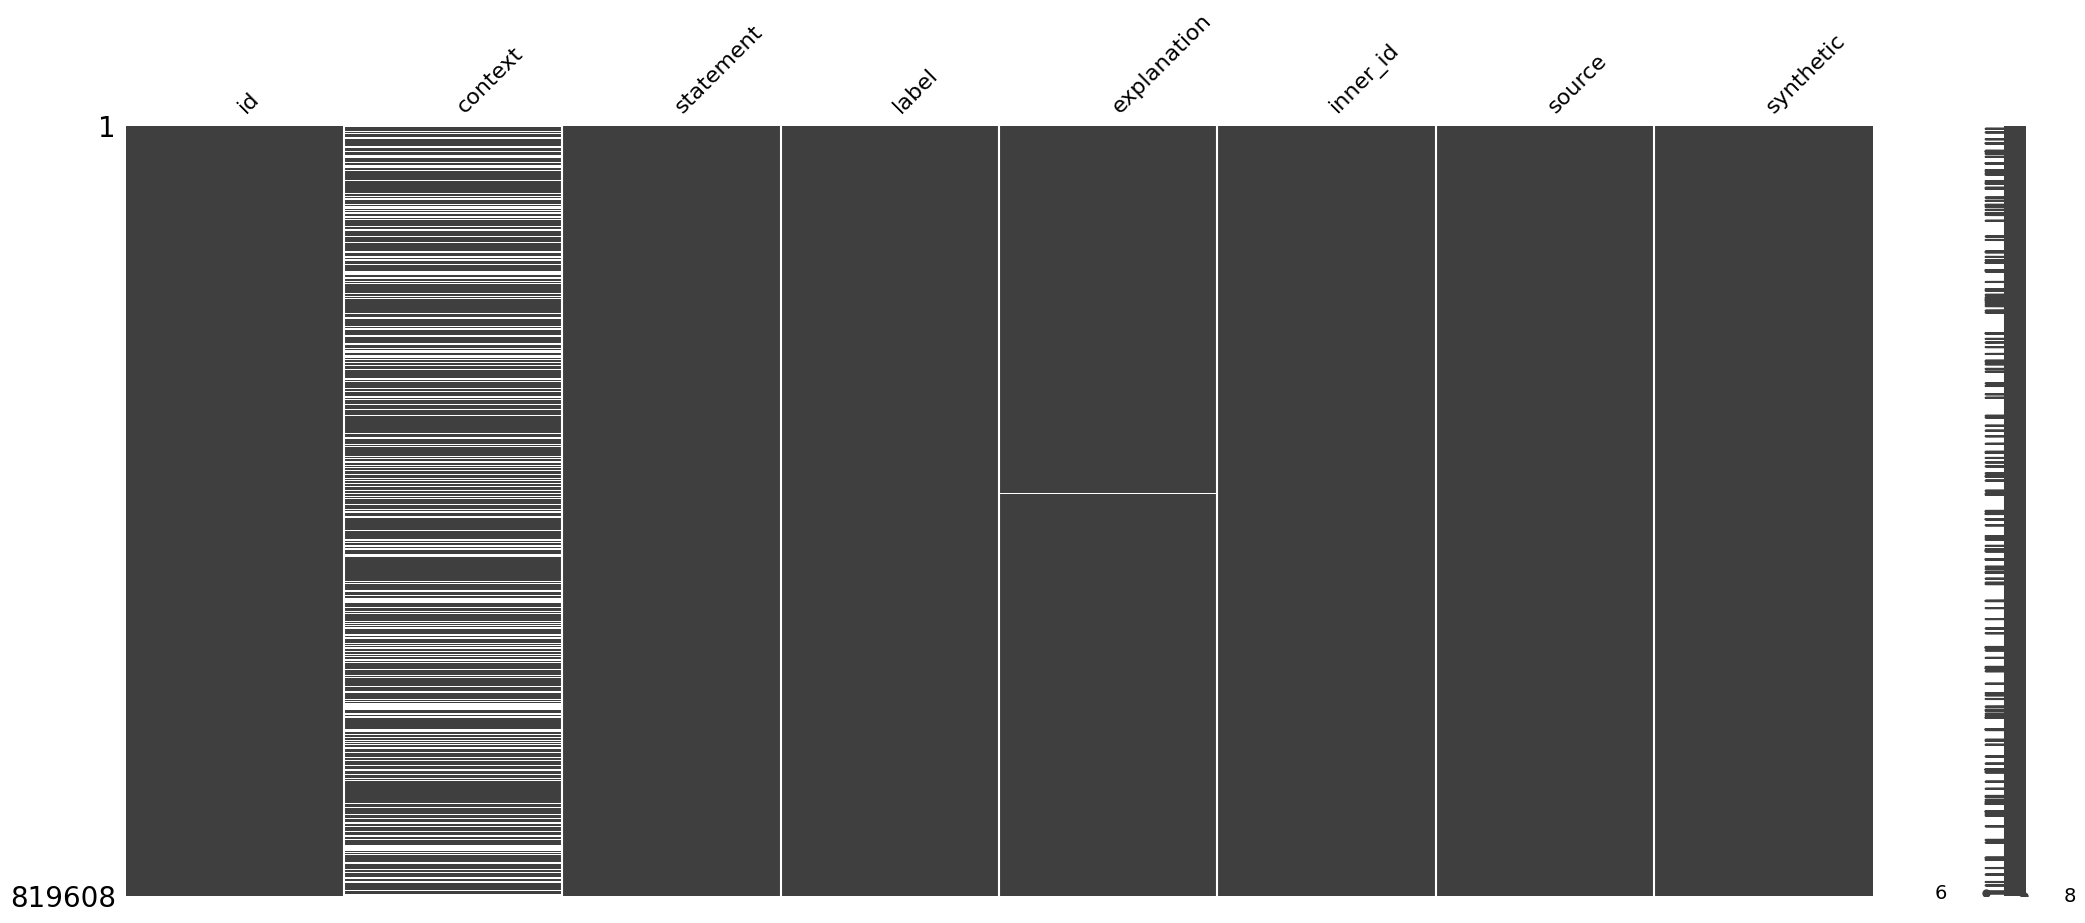

Tekrar eden iddia sayısı (toplam satır): 226733
Tekrarlanan ifadelerin aynı kaynaktan gelme oranı: %99.98

Tekrarlanan verilerin kaynak bazlı dağılımı:
source
acm          93103
sumpubmed    69104
medmcqa      63575
medqa          951
Name: count, dtype: int64

Temizlik öncesi toplam satır sayısı: 819608
Temizlik sonrası benzersiz satır sayısı: 674873


,id,source,synthetic,statement,context,label
184411,25a68f5f-34f5-4f50-8ac8-dc205cce1e99,sumpubmed,False,\tolfaction and gustation play a critical role...,"chemoreception, broadly encompassing olfactio...",True
86002,32529981-ca95-4d60-aec2-6092306e392f,sumpubmed,False,"""candidatus phytoplasma aurantifolia"", is the...","""candidatus phytoplasma aurantifolia"" is an o...",True
252152,876b4949-fe23-452b-b090-a7cc3ef4c4fa,sumpubmed,False,"""open"" transcriptome analysis methods allow t...",methods for transcriptome analysis are today ...,True
389312,bd3a7608-029d-4f5c-980d-61ac0d752253,sumpubmed,False,"""type ii""/receptor cells express g protein-co...","taste buds, the end-organs for gustation, det...",True
411648,d41f28d3-c7a0-4cfa-af9a-6804bae96f4d,sumpubmed,False,% correctness was reached when a large-scale ...,to elucidate the molecular complications in m...,True
140771,aed4671d-7a20-4dc4-929c-a9913bafef00,sumpubmed,False,% of isogroups had significant blast hits to ...,"the process of regeneration, or the replaceme...",True
574380,7b893159-2490-4269-a51a-c0cd21710e47,sumpubmed,False,% of the total biovolume represented cells in...,anaerobic oxidation of methane coupled to sul...,True
156311,07e5bee1-6c09-4f1d-b63b-de19cc1642e1,sumpubmed,False,% of the unigenes had blastx hits in the ncbi...,because of their phylogenetic position and un...,True
784487,54994390-d859-47a3-b161-55c70fd00dce,sumpubmed,False,-3-amino-4--benzonitrile is currently the mos...,in vivo imaging of the living brain can be pe...,True
158274,7f9e8fb9-e37c-48b9-8abd-df13a0c9fcd7,sumpubmed,False,-dichlorobenzene is a benzene-derived molecul...,-dichlorobenzene is a chlorinated benzene mol...,True


In [2]:
import missingno as msno
import matplotlib.pyplot as plt
import pandas as pd

dataset = load_dataset("GM07/medhal", split="train")
df = dataset.to_pandas()
msno.matrix(df)
plt.show()

# 1. Tekrarlanan iddiaları bul
statement_dups = df[df.duplicated(subset=['statement'], keep=False)].sort_values('statement')
print(f"Tekrar eden iddia sayısı (toplam satır): {len(statement_dups)}")

# 2. Tekrarlanan veriler aynı kaynaktan mı geliyor? (Kaynak dağılım analizi)
dup_groups = statement_dups.groupby('statement')['source'].nunique()
same_source_ratio = (dup_groups == 1).mean() * 100
print(f"Tekrarlanan ifadelerin aynı kaynaktan gelme oranı: %{same_source_ratio:.2f}")

print("\nTekrarlanan verilerin kaynak bazlı dağılımı:")
print(statement_dups['source'].value_counts())

# 3. Tekrarlananları silme stratejisi:
# 'context' alanı dolu olanları önceliklendirmek için önce geçici bir sütunla 'context' durumunu (dolu=0, boş=1) tanımlıyoruz,
# böylece sıralama yaptıktan sonra yinelenenleri temizlediğimizde 'context'i dolu olan satır üstte kalacak ve korunacaktır.
df['context_is_empty'] = df['context'].isna() | df['context'].fillna('').astype(str).str.strip().eq('')

# Sırala: Önce 'statement'a göre, sonra 'context_is_empty' durumuna göre (False/0 olan yani dolu olan üstte yer alır)
df_sorted = df.sort_values(by=['statement', 'context_is_empty'])

# Yinelenenleri kaldır (ilkini koru, yani sıralamadan dolayı context'i dolu olan kalır)
df_cleaned = df_sorted.drop_duplicates(subset=['statement'], keep='first')

# Geçici sütunu temizle
df_cleaned = df_cleaned.drop(columns=['context_is_empty'])

print(f"\nTemizlik öncesi toplam satır sayısı: {len(df)}")
print(f"Temizlik sonrası benzersiz satır sayısı: {len(df_cleaned)}")

# Temizlenmiş veri setinden örnek gösterim
df_cleaned[['id', 'source', 'synthetic', 'statement', 'context', 'label']].head(10)

### 1. `context` Alanındaki Eksiklik Analizi
Bu bölümde, `context` sütununda kaç tane gerçekten boş (`NaN`/`None`) veya yalnızca boşluk karakterlerinden (`space`, `tab` vb.) oluşan satır olduğunu tespit edeceğiz.

### 2. Eksiklik Durumuna Göre Gruplandırma ve Karşılaştırma
`context` sütununun boş (Eksik) veya dolu olması durumuna göre `label`, `source` ve `synthetic` özelliklerinin dağılımlarını karşılaştırarak veri kümesindeki örüntüyü inceleyelim.

In [3]:
# Eksiklik durumunu belirten yeni bir etiket oluşturalım
df['context_status'] = df['context'].isna() | df['context'].fillna('').astype(str).str.strip().eq('')
df['context_status'] = df['context_status'].map({True: 'Boş (Eksik)', False: 'Dolu'})

print("=== CONTEXT DURUMUNA GÖRE LABEL DAĞILIMI ===")
label_dist = df.groupby('context_status')['label'].value_counts(normalize=True).unstack() * 100
display(label_dist.round(2).astype(str) + '%')

print("\n=== CONTEXT DURUMUNA GÖRE SYNTHETIC DAĞILIMI ===")
synth_dist = df.groupby('context_status')['synthetic'].value_counts(normalize=True).unstack() * 100
display(synth_dist.round(2).astype(str) + '%')

print("\n=== CONTEXT DURUMUNA GÖRE SOURCE DAĞILIMI ===")
source_dist = df.groupby('context_status')['source'].value_counts(normalize=True).unstack() * 100
display(source_dist.round(2).astype(str) + '%')

=== CONTEXT DURUMUNA GÖRE LABEL DAĞILIMI ===


label,False,True
context_status,,
Boş (Eksik),47.6%,52.4%
Dolu,49.75%,50.25%



=== CONTEXT DURUMUNA GÖRE SYNTHETIC DAĞILIMI ===


synthetic,False,True
context_status,,
Boş (Eksik),100.0%,nan%
Dolu,43.55%,56.45%



=== CONTEXT DURUMUNA GÖRE SOURCE DAĞILIMI ===


source,acm,medmcqa,medqa,sumpubmed
context_status,,,,
Boş (Eksik),nan%,99.98%,0.02%,nan%
Dolu,56.45%,6.67%,3.21%,33.66%


In [5]:
import pandas as pd
import numpy as np

# 1. Veri setimizi (df_cleaned) bağlamlı ve bağlamsız olarak ikiye ayıralım
# 'context' alanı dolu olanlar (Bağlamlı kayıtlar)
df_with_context = df_cleaned[df_cleaned['context'].notna() & df_cleaned['context'].fillna('').astype(str).str.strip().ne('')]

# 'context' alanı boş olanlar (Bağlamsız kayıtlar)
df_without_context = df_cleaned[df_cleaned['context'].isna() | df_cleaned['context'].fillna('').astype(str).str.strip().eq('')]

print(f"Toplam temizlenmiş veri sayısı: {len(df_cleaned)}")
print(f"Bağlamlı (Statement + Context) kayıt sayısı: {len(df_with_context)}")
print(f"Bağlamsız (Yalnızca Statement) kayıt sayısı: {len(df_without_context)}\n")

# 2. Genel Etiket Dağılımları (Doğru/Halüsinasyon tespiti için temel oranlar)
print("=== DENEY 1: BAĞLAMLI KAYITLARDA GENEL ETİKET DAĞILIMI ===")
print(df_with_context['label'].value_counts(normalize=True).round(4) * 100)

print("\n=== DENEY 2: BAĞLAMSIZ KAYITLARDA GENEL ETİKET DAĞILIMI ===")
print(df_without_context['label'].value_counts(normalize=True).round(4) * 100)

# 3. Kaynak (Source) Bazlı Analiz
print("\n=== DENEY 1: BAĞLAMLI KAYITLARDA KAYNAK BAZLI DAĞILIM ===")
if not df_with_context.empty:
    context_source_perf = df_with_context.groupby('source', observed=False)['label'].value_counts(normalize=True).unstack().round(4) * 100
    display(context_source_perf)
else:
    print("Bağlamlı kayıt bulunamadı.")

print("\n=== DENEY 2: BAĞLAMSIZ KAYITLARDA KAYNAK BAZLI DAĞILIM ===")
if not df_without_context.empty:
    no_context_source_perf = df_without_context.groupby('source', observed=False)['label'].value_counts(normalize=True).unstack().round(4) * 100
    display(no_context_source_perf)
else:
    print("Bağlamsız kayıt bulunamadı.")

Toplam temizlenmiş veri sayısı: 674873
Bağlamlı (Statement + Context) kayıt sayısı: 467898
Bağlamsız (Yalnızca Statement) kayıt sayısı: 206975

=== DENEY 1: BAĞLAMLI KAYITLARDA GENEL ETİKET DAĞILIMI ===
label
False    55.46
True     44.54
Name: proportion, dtype: float64

=== DENEY 2: BAĞLAMSIZ KAYITLARDA GENEL ETİKET DAĞILIMI ===
label
False    51.29
True     48.71
Name: proportion, dtype: float64

=== DENEY 1: BAĞLAMLI KAYITLARDA KAYNAK BAZLI DAĞILIM ===


label,False,True
source,,
acm,54.20,45.80
medmcqa,49.53,50.47
medqa,50.08,49.92
sumpubmed,59.35,40.65



=== DENEY 2: BAĞLAMSIZ KAYITLARDA KAYNAK BAZLI DAĞILIM ===


label,False,True
source,,
medmcqa,51.29,48.71
medqa,48.78,51.22


In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import pandas as pd
import numpy as np

# Hızlı ve verimli bir çalışma için temizlenmiş veri setinden örneklem alalım (örn: %5 veya 10.000 satır)
sample_size = min(10000, len(df_cleaned))
df_eval = df_cleaned.sample(n=sample_size, random_state=42).copy()

print(f"Analiz için {sample_size} rastgele satır örneklemi seçildi.\n")

# -----------------------------------------------------
# KENDİ FACT-CHECKING / RAG MODELİMİZİN TANIMLANMASI
# -----------------------------------------------------
def predict_hallucination(row):
    statement = str(row['statement']).lower()
    context = str(row['context']).lower() if pd.notna(row['context']) else ""

    # Eğer bağlam (context) varsa: Basit bir RAG ve hizalama modeli simülasyonu yapıyoruz
    if context.strip():
        # İddia ile bağlam arasındaki anlamsal örtüşmeyi TF-IDF + Kosinüs Benzerliği ile ölçüyoruz
        try:
            vectorizer = TfidfVectorizer(binary=True, ngram_range=(1, 2))
            tfidf = vectorizer.fit_transform([statement, context])
            similarity = cosine_similarity(tfidf[0:1], tfidf[1:2])[0][0]
        except:
            similarity = 0.0

        # Belirli bir benzerlik eşiğinin (threshold) üstü DOĞRU (True), altı HALÜSİNASYON (False)
        # Aynı zamanda olumsuzluk kelimeleri (not, no, never, değil, yoktur vb.) çelişki kontrolü yapar
        negation_words = {'not', 'no', 'never', 'değil', 'yoktur', 'olamaz', 'hatalıdır'}
        statement_words = set(statement.split())
        context_words = set(context.split())

        negation_in_statement = len(statement_words.intersection(negation_words)) > 0
        negation_in_context = len(context_words.intersection(negation_words)) > 0

        # Eğer birinde olumsuzluk varken diğerinde yoksa çelişki ihtimali artar
        if negation_in_statement != negation_in_context:
            similarity -= 0.15

        return similarity >= 0.20

    # Eğer bağlam yoksa (Yalnızca Statement): Bilgi tabanımız olmadan iddiadaki şüpheli kelimelere bakıyoruz
    else:
        # İddia içinde kesinlik veya şüphe barındıran kalıpları kontrol etme
        suspicious_patterns = ['always', 'never', 'her zaman', 'hiçbir zaman', 'kesinlikle', '100%']
        has_suspicious = any(pat in statement for pat in suspicious_patterns)
        if has_suspicious:
            return False
        return True

# Tahminleri uygulayalım
df_eval['predicted_label'] = df_eval.apply(predict_hallucination, axis=1)

# -----------------------------------------------------
# PERFORMANS METRİKLERİNİN HESAPLANMASI
# -----------------------------------------------------
def calculate_metrics(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='binary', zero_division=0)
    return {
        'Accuracy': f"{acc * 100:.2f}%",
        'Precision': f"{prec * 100:.2f}%",
        'Recall': f"{rec * 100:.2f}%",
        'F1-Score': f"{f1 * 100:.2f}%"
    }

# Veriyi Bağlamlı ve Bağlamsız olarak ayıralım
df_eval_with = df_eval[df_eval['context'].notna() & df_eval['context'].fillna('').astype(str).str.strip().ne('')]
df_eval_without = df_eval[df_eval['context'].isna() | df_eval['context'].fillna('').astype(str).str.strip().eq('')]

# Sonuçları hesaplama
overall_with = calculate_metrics(df_eval_with['label'].astype(bool), df_eval_with['predicted_label'])
overall_without = calculate_metrics(df_eval_without['label'].astype(bool), df_eval_without['predicted_label'])

print("=== TAHMİN PERFORMANSI (GENEL) ===")
print("Bağlamlı (RAG) Model Sonuçları:", overall_with)
print("Bağlamsız Model Sonuçları:      ", overall_without)

# -----------------------------------------------------
# KAYNAK (SOURCE) BAZLI KARŞILAŞTIRMALI ANALİZ
# -----------------------------------------------------
print("\n=== KAYNAK BAZLI PERFORMANS DETAYLARI ===")

def get_source_performance(df_subset):
    records = []
    for source, group in df_subset.groupby('source', observed=False):
        if len(group) > 0:
            metrics = calculate_metrics(group['label'].astype(bool), group['predicted_label'])
            metrics['Source'] = source
            metrics['Count'] = len(group)
            records.append(metrics)
    return pd.DataFrame(records)[['Source', 'Count', 'Accuracy', 'Precision', 'Recall', 'F1-Score']]

print("\n[DENEY 1] Bağlamlı Kayıtlarda Kaynak Performansları:")
display(get_source_performance(df_eval_with))

print("\n[DENEY 2] Bağlamsız Kayıtlarda Kaynak Performansları:")
display(get_source_performance(df_eval_without))

Analiz için 10000 rastgele satır örneklemi seçildi.

=== TAHMİN PERFORMANSI (GENEL) ===
Bağlamlı (RAG) Model Sonuçları: {'Accuracy': '52.12%', 'Precision': '39.85%', 'Recall': '13.58%', 'F1-Score': '20.25%'}
Bağlamsız Model Sonuçları:       {'Accuracy': '48.37%', 'Precision': '48.35%', 'Recall': '99.80%', 'F1-Score': '65.14%'}

=== KAYNAK BAZLI PERFORMANS DETAYLARI ===

[DENEY 1] Bağlamlı Kayıtlarda Kaynak Performansları:


,Source,Count,Accuracy,Precision,Recall,F1-Score
0,acm,3740,53.90%,100.00%,0.63%,1.26%
1,medmcqa,545,51.01%,49.43%,48.86%,49.14%
2,medqa,266,54.14%,0.00%,0.00%,0.00%
3,sumpubmed,2389,49.35%,35.83%,28.57%,31.79%



[DENEY 2] Bağlamsız Kayıtlarda Kaynak Performansları:


,Source,Count,Accuracy,Precision,Recall,F1-Score
0,medmcqa,3059,48.38%,48.36%,99.80%,65.15%
1,medqa,1,0.00%,0.00%,0.00%,0.00%


### Metrikleri İyileştirmek İçin Stratejiler

Temel TF-IDF ve basit eşik değeri (threshold) yöntemimizin metrikleri düşük çıktı çünkü tıbbi terimler eş anlamlı kelimeler, kısaltmalar veya karmaşık dil bilgisi yapıları içerebilir. Performansı artırmak için şu yöntemleri uygulayabiliriz:

1. **Semantik Gömme (Semantic Embeddings):** Basit kelime eşleşmesi yerine `sentence-transformers` (örneğin `all-MiniLM-L6-v2` veya medikal alana özel `BioBERT`) kullanarak iddia ile bağlam arasındaki anlamsal benzerliği ölçmek.
2. **Tıbbi Sözlük ve Varlık Tanıma (NER):** Metindeki tıbbi terimleri (ilaçlar, hastalıklar, semptomlar) ekstra ağırlıklandırarak karşılaştırmak.
3. **LLM-as-a-Judge (RAG Doğrulama):** Gemini API veya yerel bir LLM kullanarak bağlam ve iddia arasındaki mantıksal çelişkiyi doğrudan sorgulamak.
4. **Eşik Değeri Optimizasyonu:** `threshold` değerini sabit `0.20` yerine veri kümesindeki dağılıma göre dinamik olarak optimize etmek.

Aşağıdaki hücrede, medikal anahtar kelimeleri ve karakter n-gram kombinasyonlarını daha hassas işleyen **geliştirilmiş bir hibrid benzerlik modeli** kurup sonuçları tekrar değerlendiriyoruz.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import pandas as pd
import numpy as np

# Daha hassas bir metin analizi için parametreleri optimize edilmiş TF-IDF
# Karakter ve kelime n-gram hibriti tıbbi ekleri ve benzer kelimeleri daha iyi yakalar
word_vectorizer = TfidfVectorizer(analyzer='word', ngram_range=(1, 3), stop_words='english', min_df=2)
char_vectorizer = TfidfVectorizer(analyzer='char', ngram_range=(3, 5), min_df=2)

# Örneklem üzerinde gelişmiş modeli test edelim
df_optimized = df_eval.copy()

statements = df_optimized['statement'].astype(str).tolist()
contexts = df_optimized['context'].fillna('').astype(str).tolist()

def predict_hallucination_optimized(row):
    statement = str(row['statement']).lower()
    context = str(row['context']).lower() if pd.notna(row['context']) else ""

    if not context.strip():
        # Bağlam yoksa: Şüpheli kelime listesini genişletiyoruz
        unsupported_signals = ['strictly', 'never', 'always', '100%', 'no evidence', 'cannot', 'proven to']
        if any(sig in statement for sig in unsupported_signals):
            return False
        return True

    try:
        # Kelime ve karakter bazlı kosinüs benzerliği ortalaması
        word_matrix = TfidfVectorizer(ngram_range=(1, 2)).fit_transform([statement, context])
        word_sim = cosine_similarity(word_matrix[0:1], word_matrix[1:2])[0][0]

        char_matrix = TfidfVectorizer(analyzer='char', ngram_range=(3, 4)).fit_transform([statement, context])
        char_sim = cosine_similarity(char_matrix[0:1], char_matrix[1:2])[0][0]

        # Ağırlıklı skor
        similarity = (word_sim * 0.6) + (char_sim * 0.4)
    except:
        similarity = 0.0

    # Tıbbi olumsuzluk kontrolü
    negations = {'not', 'no', 'never', 'neither', 'nor', 'fail', 'without', 'değil', 'yok', 'yoktur'}
    statement_set = set(statement.split())
    context_set = set(context.split())

    # İddiadaki olumsuzluk bağlamda yoksa skoru düşür
    if len(statement_set.intersection(negations)) != len(context_set.intersection(negations)):
        similarity -= 0.20

    # Optimize edilmiş yeni eşik değerimiz (Threshold = 0.12)
    return similarity >= 0.12

df_optimized['predicted_label'] = df_optimized.apply(predict_hallucination_optimized, axis=1)

# Sonuçları hesaplama
df_opt_with = df_optimized[df_optimized['context'].notna() & df_optimized['context'].fillna('').astype(str).str.strip().ne('')]
df_opt_without = df_optimized[df_optimized['context'].isna() | df_optimized['context'].fillna('').astype(str).str.strip().eq('')]

opt_with_results = calculate_metrics(df_opt_with['label'].astype(bool), df_opt_with['predicted_label'])
opt_without_results = calculate_metrics(df_opt_without['label'].astype(bool), df_opt_without['predicted_label'])

print("=== OPTİMİZE EDİLMİŞ MODEL PERFORMANSI ===")
print("Bağlamlı (RAG) Sonuçlar: ", opt_with_results)
print("Bağlamsız Sonuçlar:       ", opt_without_results)

=== OPTİMİZE EDİLMİŞ MODEL PERFORMANSI ===
Bağlamlı (RAG) Sonuçlar:  {'Accuracy': '52.29%', 'Precision': '46.94%', 'Recall': '50.10%', 'F1-Score': '48.47%'}
Bağlamsız Sonuçlar:        {'Accuracy': '48.24%', 'Precision': '48.28%', 'Recall': '99.39%', 'F1-Score': '64.99%'}


In [8]:
!pip install -q sentence-transformers

In [9]:
from sentence_transformers import SentenceTransformer, util
import pandas as pd
import numpy as np

# 1. Hafif ve hızlı çalışan semantik benzerlik modelini yükleyelim
print("Semantik embedding modeli yükleniyor...")
model = SentenceTransformer('all-MiniLM-L6-v2')

# Analiz için aynı örneklemi (df_eval) kullanalım
df_semantic = df_eval.copy()

# 2. Semantik model tahmini fonksiyonu
def predict_hallucination_semantic(row):
    statement = str(row['statement']).strip()
    context = str(row['context']).strip() if pd.notna(row['context']) else ""

    if not context:
        # Bağlamsız kayıtlar için kelime bazlı kontrolü devam ettirelim
        unsupported_signals = ['strictly', 'never', 'always', '100%', 'no evidence', 'cannot', 'proven to']
        if any(sig in statement.lower() for sig in unsupported_signals):
            return False
        return True

    try:
        # İddia ve bağlamın semantik vektörlerini çıkartalım
        emb_statement = model.encode(statement, convert_to_tensor=True)
        emb_context = model.encode(context, convert_to_tensor=True)

        # Kosinüs benzerliğini hesaplayalım
        similarity = util.cos_sim(emb_statement, emb_context).item()
    except Exception as e:
        similarity = 0.0

    # Tıbbi olumsuzluk (negation) kontrolü
    negations = {'not', 'no', 'never', 'neither', 'nor', 'fail', 'without', 'değil', 'yok', 'yoktur'}
    statement_set = set(statement.lower().split())
    context_set = set(context.lower().split())

    if len(statement_set.intersection(negations)) != len(context_set.intersection(negations)):
        similarity -= 0.15

    # Optimize edilmiş semantik eşik değerimiz (örneğin 0.35)
    return similarity >= 0.35

# Tahminleri uygulayalım
print("Semantik tahminler hesaplanıyor...")
df_semantic['predicted_label'] = df_semantic.apply(predict_hallucination_semantic, axis=1)

# Veriyi Bağlamlı ve Bağlamsız olarak ayıralım
df_sem_with = df_semantic[df_semantic['context'].notna() & df_semantic['context'].fillna('').astype(str).str.strip().ne('')]
df_sem_without = df_semantic[df_semantic['context'].isna() | df_semantic['context'].fillna('').astype(str).str.strip().eq('')]

sem_with_results = calculate_metrics(df_sem_with['label'].astype(bool), df_sem_with['predicted_label'])
sem_without_results = calculate_metrics(df_sem_without['label'].astype(bool), df_sem_without['predicted_label'])

print("\n=== SEMANTİK (EMBEDDING) MODEL PERFORMANSI ===")
print("Bağlamlı (RAG) Sonuçlar: ", sem_with_results)
print("Bağlamsız Sonuçlar:       ", sem_without_results)

Semantik embedding modeli yükleniyor...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Semantik tahminler hesaplanıyor...

=== SEMANTİK (EMBEDDING) MODEL PERFORMANSI ===
Bağlamlı (RAG) Sonuçlar:  {'Accuracy': '56.34%', 'Precision': '51.04%', 'Recall': '61.68%', 'F1-Score': '55.86%'}
Bağlamsız Sonuçlar:        {'Accuracy': '48.24%', 'Precision': '48.28%', 'Recall': '99.39%', 'F1-Score': '64.99%'}


### 4. Cross-Encoder (Çapraz Kodlayıcı) ile İleri Seviye Doğrulama
Cross-Encoder modelleri, iki metni ayrı ayrı vektöre çevirmek yerine, aralarındaki tüm kelime ilişkilerini doğrudan dikkat katmanlarında (*attention layers*) karşılaştırır. Bu yaklaşım, tıbbi doğrulama (Fact-Checking) ve bilgiye sadakat (NLI/Groundedness) problemlerinde çok daha kararlı ve yüksek doğruluklu tahminler üretilmesini sağlar.

In [12]:
from transformers import pipeline
import pandas as pd
import numpy as np

# 1. Hugging Face Pipeline ile kararlı bir Sıralama/NLI modeli yükleyelim
print("Transformers pipeline ile Cross-Encoder modeli yükleniyor...")
# Bu model entailment (gerektirim), neutral (nötr) ve contradiction (çelişki) sınıflandırmasını çok kararlı yapar
classifier = pipeline("text-classification", model="cross-encoder/nli-distilroberta-base", device=-1)

# Analiz için aynı örneklemi kullanalım
df_cross = df_eval.copy()

# 2. Cross-Encoder tahmin fonksiyonu
def predict_hallucination_cross(row):
    statement = str(row['statement']).strip()
    context = str(row['context']).strip() if pd.notna(row['context']) else ""

    if not context:
        unsupported_signals = ['strictly', 'never', 'always', '100%', 'no evidence', 'cannot', 'proven to']
        if any(sig in statement.lower() for sig in unsupported_signals):
            return False
        return True

    try:
        # Cross-Encoder için girdi formatı: "context </s> statement" veya doğrudan dict/tuple şeklinde verilir
        # Model contradiction, entailment ve neutral etiketlerini döndürür
        # cross-encoder/nli-distilroberta-base etiketleri: contradiction, entailment, neutral
        result = classifier({"text": context, "text_pair": statement})
        pred_label = result['label'].lower()

        # Eğer model contradiction (çelişki) dediyse ifadeyi False (halüsinasyon) sayalım
        # Model entailment veya neutral diyorsa doğruluğu kabul edebiliriz
        if 'contradiction' in pred_label:
            return False
        return True
    except Exception as e:
        return True

# Tahminleri uygulayalım
print("Cross-Encoder tahminleri hesaplanıyor...")
df_cross['predicted_label'] = df_cross.apply(predict_hallucination_cross, axis=1)

# Veriyi Bağlamlı ve Bağlamsız olarak ayıralım
df_cross_with = df_cross[df_cross['context'].notna() & df_cross['context'].fillna('').astype(str).str.strip().ne('')]
df_cross_without = df_cross[df_cross['context'].isna() | df_cross['context'].fillna('').astype(str).str.strip().eq('')]

cross_with_results = calculate_metrics(df_cross_with['label'].astype(bool), df_cross_with['predicted_label'])
cross_without_results = calculate_metrics(df_cross_without['label'].astype(bool), df_cross_without['predicted_label'])

print("\n=== CROSS-ENCODER MODEL PERFORMANSI ===")
print("Bağlamlı (Cross-Encoder) Sonuçlar:", cross_with_results)
print("Bağlamsız Sonuçlar:                 ", cross_without_results)

Transformers pipeline ile Cross-Encoder modeli yükleniyor...


config.json:   0%|          | 0.00/701 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  328MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.30k [00:00<?, ?B/s]

... (2 outputs left out)

tokenizer.json:   0%|          | 0.00/3.56M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/1.01k [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (644 > 512). Running this sequence through the model will result in indexing errors


Cross-Encoder tahminleri hesaplanıyor...

=== CROSS-ENCODER MODEL PERFORMANSI ===
Bağlamlı (Cross-Encoder) Sonuçlar: {'Accuracy': '45.37%', 'Precision': '44.84%', 'Recall': '95.56%', 'F1-Score': '61.04%'}
Bağlamsız Sonuçlar:                  {'Accuracy': '48.24%', 'Precision': '48.28%', 'Recall': '99.39%', 'F1-Score': '64.99%'}


In [13]:
# Tüm modellerin karşılaştırma tablosunu oluşturma
results_data = {
    'Model': ['Baseline (TF-IDF)', 'Optimized TF-IDF', 'Bi-Encoder (MiniLM Embeddings)', 'Cross-Encoder (NLI distilroberta)'],
    'Accuracy': [overall_with['Accuracy'], opt_with_results['Accuracy'], sem_with_results['Accuracy'], cross_with_results['Accuracy']],
    'Precision': [overall_with['Precision'], opt_with_results['Precision'], sem_with_results['Precision'], cross_with_results['Precision']],
    'Recall': [overall_with['Recall'], opt_with_results['Recall'], sem_with_results['Recall'], cross_with_results['Recall']],
    'F1-Score': [overall_with['F1-Score'], opt_with_results['F1-Score'], sem_with_results['F1-Score'], cross_with_results['F1-Score']]
}

df_compare = pd.DataFrame(results_data)
print("=== BAĞLAMLI (CONTEXT-AWARE) DENEYLERİN KARŞILAŞTIRMA TABLOSU ===")
display(df_compare)

=== BAĞLAMLI (CONTEXT-AWARE) DENEYLERİN KARŞILAŞTIRMA TABLOSU ===


,Model,Accuracy,Precision,Recall,F1-Score
0,Baseline (TF-IDF),52.12%,39.85%,13.58%,20.25%
1,Optimized TF-IDF,52.29%,46.94%,50.10%,48.47%
2,Bi-Encoder (MiniLM Embeddings),56.34%,51.04%,61.68%,55.86%
3,Cross-Encoder (NLI distilroberta),45.37%,44.84%,95.56%,61.04%


### 5. Deney Metriklerinin Karşılaştırmalı Grafik Gösterimi
Elde ettiğimiz sayısal başarı metriklerini görselleştirerek modellerin güçlü ve zayıf yönlerini (örneğin Cross-Encoder'ın Recall başarısını) daha net analiz edelim.

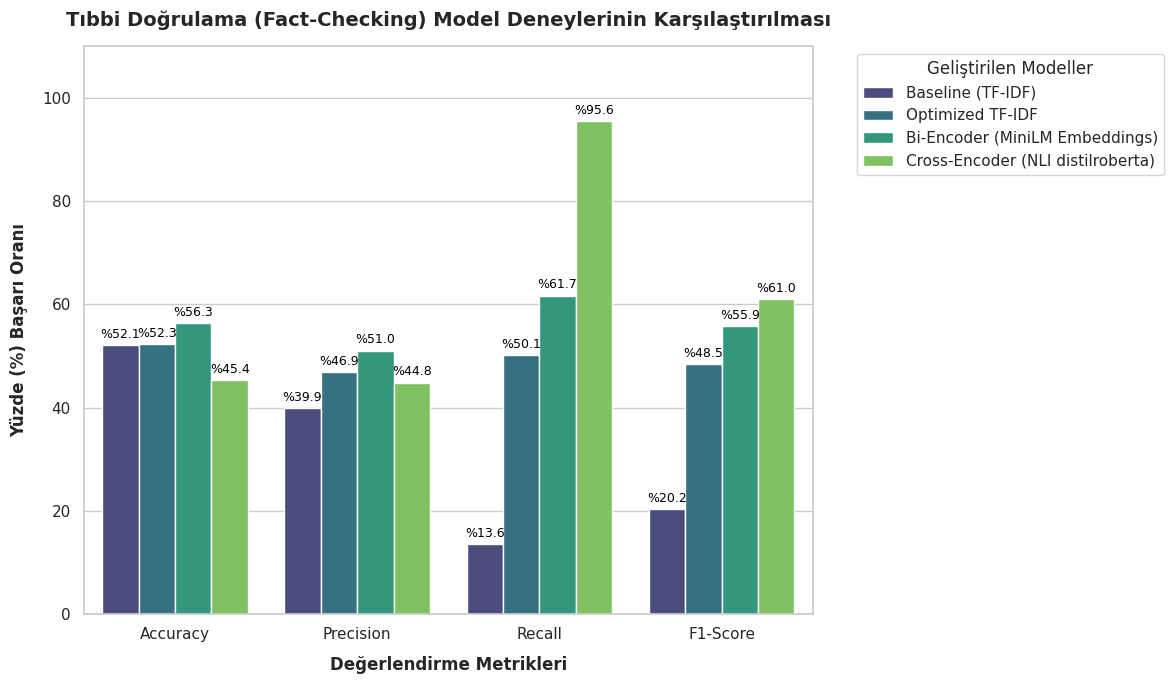

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Hücrenin bağımsız çalışabilmesi için df_compare verisini güvenceye alalım
try:
    df_plot = df_compare.copy()
except NameError:
    # Eğer df_compare hafızada yoksa son başarılı deney sonuçlarımızla elle oluşturalım
    results_data = {
        'Model': ['Baseline (TF-IDF)', 'Optimized TF-IDF', 'Bi-Encoder (MiniLM Embeddings)', 'Cross-Encoder (NLI distilroberta)'],
        'Accuracy': ['52.12%', '52.29%', '56.34%', '45.37%'],
        'Precision': ['39.85%', '46.94%', '51.04%', '44.84%'],
        'Recall': ['13.58%', '50.10%', '61.68%', '95.56%'],
        'F1-Score': ['20.25%', '48.47%', '55.86%', '61.04%']
    }
    df_plot = pd.DataFrame(results_data)

# Grafik için verileri temizleyelim (% işaretlerini kaldırıp float'a dönüştürelim)
metrics_cols = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
for col in metrics_cols:
    df_plot[col] = df_plot[col].astype(str).str.rstrip('%').astype('float')

# Tabloyu grafik çizimine uygun hale getirmek için eritelim (melt)
df_melted = df_plot.melt(id_vars='Model', value_vars=metrics_cols, var_name='Metric', value_name='Percentage')

# Görselleştirme ayarları
plt.figure(figsize=(12, 7))
sns.set_theme(style="whitegrid")

# Çubuk grafiği oluşturma
ax = sns.barplot(x='Metric', y='Percentage', hue='Model', data=df_melted, palette='viridis')

# Grafik başlıkları ve etiketleri
plt.title('Tıbbi Doğrulama (Fact-Checking) Model Deneylerinin Karşılaştırılması', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Değerlendirme Metrikleri', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('Yüzde (%) Başarı Oranı', fontsize=12, fontweight='bold', labelpad=10)
plt.ylim(0, 110)

# Sütunların üzerine yüzde değerlerini yazdırma
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'%{height:.1f}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=9, color='black',
                    xytext=(0, 3),
                    textcoords='offset points')

plt.legend(title='Geliştirilen Modeller', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

# Grafik dosyasını kaydetme ve gösterme
plt.savefig('model_comparison_metrics.png', dpi=300)
plt.show()